# 2. Particle in a Rectangular Well

## 2.1 Objective

To investigate the quantum mechanical behaviour of a particle in a one-dimensional rectangular well with walls of finite potential.

## 2.2 Physical Model

A particle of mass $m$ is confined in a one-dimensional well of length $l$ having two walls of finite potential, as given by

\begin{equation}
    V =
    \begin{cases}
        V_0, & x<0 & \text{(Region I)}\\
        0, & 0 \leqslant x \leqslant l & \text{(Region  II)}\\
        V_0, & x > l & \text{(Region  III)}
    \end{cases}
\end{equation}

In [66]:
# Importing libraries

import numpy as np
import matplotlib.pyplot as plt
from scipy import constants as const
from scipy.optimize import brentq

In [135]:
# Physical constants
m = const.m_e
hbar = const.hbar

# Parameters
l = 2e-10   # Width of the well
V0 = 10     # Barrier height in eV
V0_J = V0 * const.e

# Generating points
x = np.linspace(-l, 2*l, 1000)

# Potential energy
# np.where(condition, value if true, value if false)
# NumPy uses '&' instead of 'AND'
V = np.where((x>=0) & (x <=l), 0, V0)

#or, use

# V = []
# for position in x:
#    if 0 <= position <= l:
#        V.append(0)
#    else:
#        V.append(V0)
# V = np.array(V)


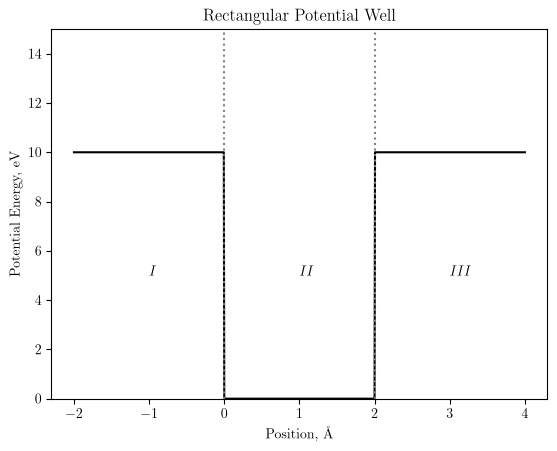

In [136]:
# Potential Energy Plot

plt.rcParams.update({"text.usetex": True, "font.family": "serif"})

plt.plot(x * 1e10, V, color = "k")

plt.ylim(0,15)
plt.text(-1,5, "$I$")
plt.text(1,5, "$II$")
plt.text(3,5, "$III$")

plt.xlabel(r"Position, \AA")
plt.ylabel("Potential Energy, eV")
plt.title("Rectangular Potential Well")

plt.axvline(0, linestyle=":", color="gray")
plt.axvline(l*1e10, linestyle=":", color="gray")

plt.show()


## 2.3 Theory and Code

### 2.3.1 Allowed Energy Eigenvalues

The Schrödinger equation for each region can be derived as

\begin{equation}
    \psi_{I} = Ce^{\alpha x} \\
\end{equation}


\begin{equation}
    \psi_{II} = A\cos(kx) + B sin(kx) \\
\end{equation}

\begin{equation}
    \psi_{III} = Ge^{-\alpha (x-l)}
\end{equation}
where $\alpha$ and $k$ represent the **_decay constant_** and **_wave number_** respectively.
$$
\alpha = \frac{\sqrt{2m(V_0 - E)}}{\hbar^2}
$$

$$
k = \frac{\sqrt{2mE}}{\hbar^2}
$$

By applying boundary conditions, $x = 0$ and $x= l$, the following equation is obtained.

$$
(\alpha^2 - k^2)\sin(kl) + 2\alpha k \cos(kl) = 0
$$

or,

$$
f(E) = (\beta^2 - z^2)\sin(z) + 2\beta z \cos(z) = 0
$$
where $z = kl$ and $\beta = \alpha l$

The allowed energy eigenvalues are the roots of the equation when $f(E) = 0$.


In [137]:
# Energy function
def energy_eq(e_ev):

    E = e_ev * const.e
    k = np.sqrt(2*m*E)/hbar
    alpha = np.sqrt(2*m*(V0_J - E))/ hbar
    z = k * l
    beta =alpha * l

    return (beta**2 - z**2) * np.sin(z) + 2*beta*z*np.cos(z)


In [138]:
# For the bound state 0 < E < V_0

# Energy values slightly above zero to slightly less than V_0
energies = np.linspace(1e-6, V0 - 1e-6, 1000)
values = energy_eq(energies)

roots = []

# Checking for the roots of the equation, based on intervals.
for i in range(len(energies)-1):
    if values[i]*values[i+1] < 0:
        # if it is negative, that means the sign has changed --> inflection --> root
        root = brentq(energy_eq, energies[i], energies[i+1])
        roots.append(root)

print("Allowed energy eigenvalues:")
for n, E in enumerate(roots, start = 1):
    print(f"State {n}: {E:.6f} eV")


Allowed energy eigenvalues:
State 1: 3.414728 eV
State 2: 9.977486 eV


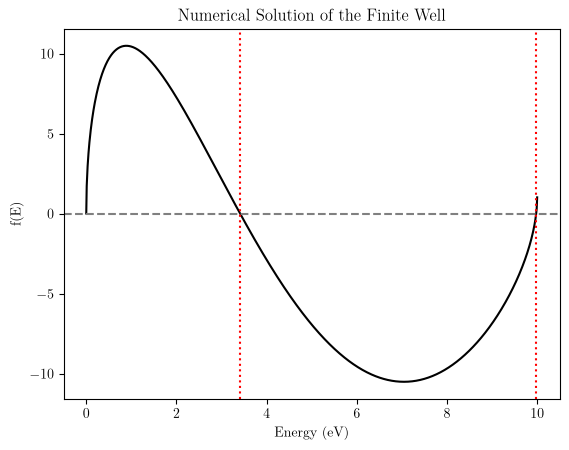

In [139]:
plt.plot(energies, values, color = "k")
plt.axhline(0, linestyle="--", color="gray")

for E in roots:
    plt.axvline(E, color = "red", linestyle = ":")

plt.xlabel("Energy (eV)")
plt.ylabel("f(E)")
plt.title("Numerical Solution of the Finite Well")

plt.show()


#### 2.3.1.1 Result

- Two roots have been determined for a finite rectangular well of length 2Å.
- These roots represent the allowed energy eigenvalues for the ground and first excited states of the wave function respectively.

### 2.3.2 Wavefunction of the Rectangular Well

In order to determine the wavefunction, the constants $C$, $A$, $B$, and $G$ must be calculated. Since $\psi$ must be continuous and would have a first derivative, the following are obtained when boundary conditions are applied:
$$
C = A
$$

$$
B = \frac{\alpha}{k}
$$

$$
G = A\cos(kl) + B\sin(kl)
$$

The wavefunction is thus calculated in regions $I$, $II$, and $III$ separately, and then combined and normalised.

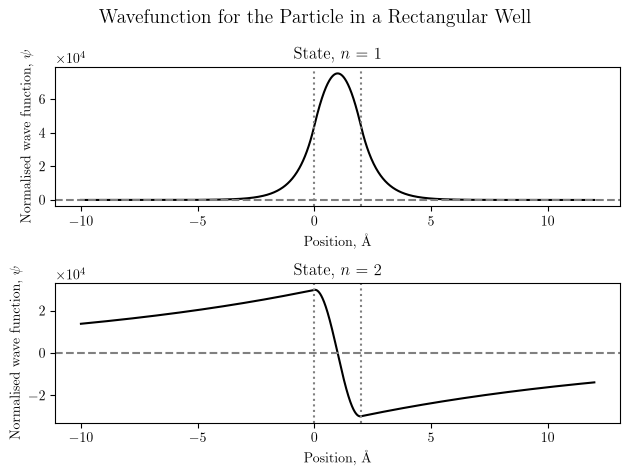

In [149]:
# Initialising the figure
fig, axes = plt.subplots(len(roots),1)
fig.suptitle("Wavefunction for the Particle in a Rectangular Well", fontsize = 14)

# Combining the loops for the roots and the subplots
for n, (E_eV, ax) in enumerate(zip(roots, axes.flat), start = 1):

    # Formulae
    E = E_eV * const.e
    k = (np.sqrt(2*m*E))/hbar
    alpha = (np.sqrt(2*m*(V0_J - E)))/hbar

    # Values of constants
    A = 1
    B = alpha/k
    G = A*np.cos(k*l) + B*np.sin(k*l)

    # Position arrays
    x_I = np.linspace(-5*l, 0, 500)
    x_II = np.linspace(0, l, 250)
    x_III = np.linspace(l, 6*l, 500)

    # Wavefunctions for each region
    psi_I = A*np.exp(alpha*x_I)
    psi_II = A*np.cos(k*x_II) + B*np.sin(k*x_II)
    psi_III = G*np.exp(-alpha*(x_III-l))

    # Combining the regions
    x_all = np.concatenate((x_I, x_II, x_III))
    psi_all = np.concatenate((psi_I, psi_II, psi_III))

    # Normalising the wavefunction
    N = np.sqrt(np.trapezoid(psi_all**2, x_all))
    psi_normalised = psi_all/N

    # Plot
    ax.plot(x_all * 1e10, psi_normalised, color = "k")
    ax.set_title(f"State, $n$ = {n}")
    ax.axvline(0, linestyle=":", color="gray")
    ax.axvline(l*1e10, linestyle=":", color="gray")
    ax.axhline(0, linestyle="--", color="gray")
    ax.set_xlabel(r"Position, \AA")
    ax.set_ylabel(r"Normalised wave function, $\psi$")
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

plt.tight_layout()
plt.show()

#### 2.3.2.1 Result
- The interior of the finite potential well shows the same number of nodes for the ground and excited states as the one-dimensional box.
- However, $\psi \rightarrow 0$ as $x \rightarrow \pm \infty$. This is opposed to the one-dimensional box, where $\psi = 0$ at the boundaries.
- There exists a finite, non-zero probability of finding the electron outside the walls even when the potential energy of the particle is less than $V_0$, a classically forbidden result. This quantum phenomenon is referred to as **_tunneling_**.